# Auditoria dos CSVs de trafego (ANTT)

Primeira olhada nos dados brutos: schema, encoding, tipos.
Fase F1/F2 do plano de tarefas.

In [1]:
import pandas as pd
from pathlib import Path

print('pandas', pd.__version__)

pandas 3.0.6


In [3]:
ARQ = Path("../data/raw/volume_pedagio_2026.csv")

df = pd.read_csv(ARQ, sep=';', encoding='latin-1', decimal=',', nrows=100);

print(df.shape)
print(df.dtypes)

df.head()

(100, 8)
concessionaria         str
mes_ano                str
sentido                str
praca                  str
tipo_cobranca          str
categoria_eixo       int64
tipo_de_veiculo        str
volume_total       float64
dtype: object


,concessionaria,mes_ano,sentido,praca,tipo_cobranca,categoria_eixo,tipo_de_veiculo,volume_total
0,AUTOPISTA FLUMINENSE,01/01/2026,Crescente,Casimiro de Abreu,Automática,2,Comercial,135.0
1,AUTOPISTA FLUMINENSE,01/01/2026,Crescente,Casimiro de Abreu,Automática,2,Passeio,3051.0
2,AUTOPISTA FLUMINENSE,01/01/2026,Crescente,Casimiro de Abreu,Automática,3,Comercial,142.0
3,AUTOPISTA FLUMINENSE,01/01/2026,Crescente,Casimiro de Abreu,Automática,3,Passeio,7.0
4,AUTOPISTA FLUMINENSE,01/01/2026,Crescente,Casimiro de Abreu,Automática,4,Comercial,155.0


In [4]:
for ano in [2024, 2025, 2026]:
    arq = Path(f"../data/raw/volume_pedagio_{ano}.csv")
    df = pd.read_csv(arq, sep=';', decimal = ',', encoding = 'latin-1', nrows=100_000);
    print("Ano:", ano, " | Shape:", df.shape)
    print(df.dtypes)
    print("-" * 40)

Ano: 2024  | Shape: (100000, 8)
concessionaria         str
mes_ano                str
sentido                str
praca                  str
tipo_cobranca          str
categoria_eixo       int64
tipo_de_veiculo        str
volume_total       float64
dtype: object
----------------------------------------
Ano: 2025  | Shape: (100000, 8)
concessionaria         str
mes_ano                str
sentido                str
praca                  str
tipo_cobranca          str
categoria_eixo       int64
tipo_de_veiculo        str
volume_total       float64
dtype: object
----------------------------------------
Ano: 2026  | Shape: (100000, 8)
concessionaria         str
mes_ano                str
sentido                str
praca                  str
tipo_cobranca          str
categoria_eixo       int64
tipo_de_veiculo        str
volume_total       float64
dtype: object
----------------------------------------


In [5]:
# os conjuntos de valores de sentido, tipo_cobranca e tipo_de_veiculo são iguais nos 3 anos?

from pathlib import Path
import pandas as pd

COLS = ["sentido", "tipo_cobranca", "tipo_de_veiculo"]

for ano in [2024, 2025, 2026]:
    arq = Path(f"../data/raw/volume_pedagio_{ano}.csv")
    df = pd.read_csv(arq, sep=";", encoding="latin-1", usecols=COLS)
    print("=== Ano", ano, "| linhas:", len(df))
    for c in COLS:
        print("  ", c, "->", sorted(df[c].unique()))


=== Ano 2024 | linhas: 3312763
   sentido -> ['Crescente', 'Decrescente']
   tipo_cobranca -> ['Automática', 'Manual', 'OCR/PLACA']
   tipo_de_veiculo -> ['Comercial', 'Moto', 'Passeio', 'Veículo Pequeno']
=== Ano 2025 | linhas: 3274157
   sentido -> ['Crescente', 'Decrescente']
   tipo_cobranca -> ['Automática', 'Manual', 'OCR/PLACA']
   tipo_de_veiculo -> ['Comercial', 'Moto', 'Passeio']
=== Ano 2026 | linhas: 2597234
   sentido -> ['Crescente', 'Decrescente']
   tipo_cobranca -> ['Automática', 'Manual', 'OCR/PLACA']
   tipo_de_veiculo -> ['Comercial', 'Moto', 'Passeio']


In [6]:
# como foi encontrado um tipo de veículo único em 2024 que não estava nos outros anos, vamos verificar se o valor ou quantidade de ocorrências desse tipo de veículo é relevante para o modelo. 
# Se for irrelevante, podemos simplesmente removê-lo do dataset.

ARQ = Path("../data/raw/volume_pedagio_2024.csv")

df = pd.read_csv(
    ARQ,
    sep=";",
    encoding="latin-1",
    decimal=",",
    usecols=["tipo_de_veiculo", "volume_total"], 
)

mascara = df["tipo_de_veiculo"] == "Veículo Pequeno"
print("linhas de Veiculo Pequeno:", mascara.sum())

vol_pequeno = df.loc[mascara, "volume_total"].sum()
vol_total = df["volume_total"].sum()

print("Veiculo Pequeno:", vol_pequeno)
print("Total 2024 .....:", vol_total)
print("Participacao ...:", vol_pequeno / vol_total)




linhas de Veiculo Pequeno: 7
Veiculo Pequeno: 7.0
Total 2024 .....: 834732408.0
Participacao ...: 8.385920964506268e-09


In [7]:
# unificando arquivos de 2024, 2025 e 2026 em um único dataset

from pathlib import Path
import pandas as pd

frames = []
for ano in [2024, 2025, 2026]:
    arq = Path(f"../data/raw/volume_pedagio_{ano}.csv")
    df = pd.read_csv(arq, sep=";", encoding="latin-1", decimal=",")
    df["ano_origem"] = ano
    frames.append(df)
    print("lido", ano, "->", df.shape)

dados = pd.concat(frames, ignore_index=True)
print("TOTAL:", dados.shape)

lido 2024 -> (3312763, 9)


C:\Users\danielflavio\AppData\Local\Temp\ipykernel_3696\4093368789.py:9: DtypeWarning: Columns (5: categoria_eixo) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(arq, sep=";", encoding="latin-1", decimal=",")


lido 2025 -> (3274157, 9)
lido 2026 -> (2597234, 9)
TOTAL: (9184154, 9)


In [ ]:
# Destrinchar o categoria_eixo para verificar se há alguma inconsistência nos dados

for ano in [2024, 2025, 2026]:
    arq = Path(f"../data/raw/volume_pedagio_{ano}.csv")
    df = pd.read_csv(arq, sep=";", encoding="latin-1", usecols=["categoria_eixo"], dtype="str")
    valores = df["categoria_eixo"]

    # tenta converter para numero; o que nao for numero vira NaN (vazio)
    numero = pd.to_numeric(valores, errors="coerce")

    suspeitos = valores[numero.isna()].unique()

    print(ano, "->", suspeitos)

In [ ]:
arq = Path("../data/raw/volume_pedagio_2025.csv")
df = pd.read_csv(arq, sep=";", encoding="latin-1", usecols=["mes_ano", "categoria_eixo"], dtype="str")

numero = pd.to_numeric(df["categoria_eixo"], errors="coerce")
eh_texto = numero.isna()

print("total .....:", len(df))
print("numerico ..:", (~eh_texto).sum())
print("texto .....:", eh_texto.sum())
print("\npor mes (dd/mm/aaaa), so as linhas de texto:")
print(df.loc[eh_texto, "mes_ano"].value_counts().sort_index())

In [ ]:
# Verifica se existe dados duplicados na virada do ano

KEY = ["concessionaria", "mes_ano", "sentido", "praca",
       "tipo_cobranca", "categoria_eixo", "tipo_de_veiculo"]

for ano in [2024, 2025, 2026]:
    arq = Path(f"../data/raw/volume_pedagio_{ano}.csv")
    df = pd.read_csv(arq, sep=";", encoding="latin-1", usecols=KEY, dtype="str")

    anos = sorted(df["mes_ano"].str[-4:].unique())   # ultimos 4 chars = o ano
    dup = int(df.duplicated().sum())                # linhas com chave repetida

    print(f"{ano}: anos presentes={anos} | duplicadas={dup}")

In [ ]:
# detalhando duplicidades
KEY = ["concessionaria", "mes_ano", "sentido", "praca",
       "tipo_cobranca", "categoria_eixo", "tipo_de_veiculo"]

arq = Path("../data/raw/volume_pedagio_2025.csv")
dtype = {c: "str" for c in KEY}          # categoria_eixo como texto: evita o DtypeWarning

df = pd.read_csv(arq, sep=";", encoding="latin-1",
                 usecols=KEY + ["volume_total"], dtype=dtype, decimal=",")

print("duplicadas na chave ....:", int(df.duplicated(subset=KEY).sum()))
print("duplicadas exatas ......:", int(df.duplicated().sum()))   # inclui o volume

dups = df[df.duplicated(subset=KEY, keep=False)].sort_values(KEY)
print("linhas em grupos duplicados:", len(dups))
print()
print(dups.head(12))
print()
print("por mes:")
print(dups["mes_ano"].str[3:].value_counts().sort_index())

In [ ]:
print("colunas do arquivo:", list(df.columns))

# quantas linhas tem cada chave repetida? (esperamos grupos de 2)
grupos = df[df.duplicated(subset=KEY, keep=False)]
print("\ntamanho dos grupos duplicados:")
print(grupos.groupby(KEY).size().value_counts())

# mostra TODAS as linhas de uma chave repetida
primeira = grupos.iloc[0]
mesma_chave = (df[KEY] == primeira[KEY]).all(axis=1)
print("\nlinhas dessa chave:")
print(df.loc[mesma_chave, KEY + ["volume_total"]])

In [ ]:
pd.Series(["2", "10", "Veículo Comercial 2 eixos"]).astype("int64")

## Volume medio por dia da semana

Esta e a figura de apoio dos slides. Ela sustenta o achado **"a serie e diaria"**:
o movimento cai no fim de semana (barras vermelhas), entao modelar por mes jogaria
essa informacao fora. Usa a serie diaria ja consolidada (`series_praca_dia.parquet`),
considerando apenas os dias efetivamente observados.

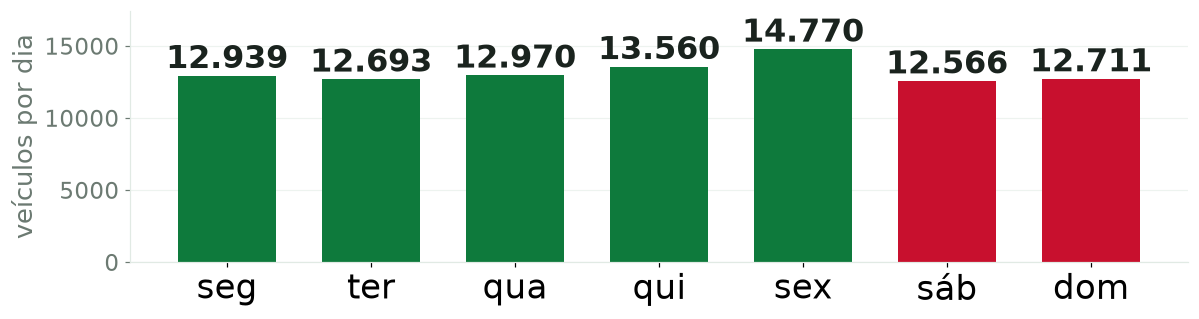

: 

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

SERIE = Path("../data/series_praca_dia.parquet")

s = pd.read_parquet(SERIE)[["data", "Total", "observado"]]
s = s[s["observado"]]
media = s.assign(dow=s["data"].dt.dayofweek).groupby("dow")["Total"].mean()

rotulos = ["seg", "ter", "qua", "qui", "sex", "s\u00e1b", "dom"]
cores = ["#0E7A3C"] * 5 + ["#C8102E", "#C8102E"]

fig, ax = plt.subplots(figsize=(11, 3.0), dpi=110)
barras = ax.bar(rotulos, media.values, color=cores, width=0.68)
for b, v in zip(barras, media.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,.0f}".replace(",", "."),
            ha="center", va="bottom", fontsize=21, fontweight="bold", color="#1A231E")

ax.set_ylim(0, media.max() * 1.18)
ax.set_ylabel("ve\u00edculos por dia", fontsize=17, color="#6C7A72")
ax.tick_params(axis="x", labelsize=22)
ax.tick_params(axis="y", labelsize=15, colors="#6C7A72")
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.spines["left"].set_color("#E1EAE4")
ax.spines["bottom"].set_color("#E1EAE4")
ax.grid(axis="y", color="#EDF3EF")
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()